In [1]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

def load_img(path_to_img, max_dim=512):
    img = tf.io.read_file(path_to_img)
    img = tf.image.decode_image(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)
    shape = tf.cast(tf.shape(img)[:-1], tf.float32)
    long_dim = max(shape)
    scale = max_dim / long_dim
    new_shape = tf.cast(shape * scale, tf.int32)
    img = tf.image.resize(img, new_shape)
    return img[tf.newaxis, :]

def clip_0_1(image):
    return tf.clip_by_value(image, clip_value_min=0.0, clip_value_max=1.0)

content_path = tf.keras.utils.get_file('YellowLabradorLooking_new.jpg', 'https://storage.googleapis.com/download.tensorflow.org/example_images/YellowLabradorLooking_new.jpg')
style_path = tf.keras.utils.get_file('kandinsky5.jpg','https://storage.googleapis.com/download.tensorflow.org/example_images/Vassily_Kandinsky%2C_1913_-_Composition_7.jpg')

content_image = load_img(content_path)
style_image = load_img(style_path)


In [2]:
# 3. Model Architecture (VGG19)
def vgg_layers(layer_names):
    vgg = tf.keras.applications.VGG19(include_top=False, weights='imagenet')
    vgg.trainable = False
    outputs = [vgg.get_layer(name).output for name in layer_names]
    return tf.keras.Model([vgg.input], outputs)

content_layers = ['block5_conv2']
style_layers = ['block1_conv1', 'block2_conv1', 'block3_conv1', 'block4_conv1', 'block5_conv1']

num_content_layers = len(content_layers)
num_style_layers = len(style_layers)

class StyleContentModel(tf.keras.models.Model):
    def __init__(self, style_layers, content_layers):
        super(StyleContentModel, self).__init__()
        self.vgg = vgg_layers(style_layers + content_layers)
        self.style_layers = style_layers
        self.content_layers = content_layers
        self.num_style_layers = len(style_layers)
        self.vgg.trainable = False

    def call(self, inputs):
        inputs = inputs * 255.0
        preprocessed_input = tf.keras.applications.vgg19.preprocess_input(inputs)
        outputs = self.vgg(preprocessed_input)
        style_outputs, content_outputs = (outputs[:self.num_style_layers], outputs[self.num_style_layers:])
        
        style_dict = {style_name: self.gram_matrix(value) for style_name, value in zip(self.style_layers, style_outputs)}
        content_dict = {content_name: value for content_name, value in zip(self.content_layers, content_outputs)}
        return {'style': style_dict, 'content': content_dict}

    def gram_matrix(self, input_tensor):
        result = tf.linalg.einsum('bijc,bijd->bcd', input_tensor, input_tensor)
        input_shape = tf.shape(input_tensor)
        num_locations = tf.cast(input_shape[1]*input_shape[2], tf.float32)
        return result / num_locations

In [3]:
# 4. Initialization and Target Setup
extractor = StyleContentModel(style_layers, content_layers)
style_targets = extractor(style_image)['style']
content_targets = extractor(content_image)['content']

image = tf.Variable(content_image)
opt = tf.keras.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

style_weight = 1e-2
content_weight = 1e4
tv_weight = 30

@tf.function()
def train_step(image):
    with tf.GradientTape() as tape:
        outputs = extractor(image)
        style_loss = tf.add_n([tf.reduce_mean((outputs['style'][name] - style_targets[name])**2) for name in outputs['style'].keys()])
        style_loss *= style_weight / num_style_layers
        
        content_loss = tf.add_n([tf.reduce_mean((outputs['content'][name] - content_targets[name])**2) for name in outputs['content'].keys()])
        content_loss *= content_weight / num_content_layers
        
        tv_loss = tv_weight * tf.image.total_variation(image)
        loss = style_loss + content_loss + tv_loss

    grad = tape.gradient(loss, image)
    opt.apply_gradients([(grad, image)])
    image.assign(clip_0_1(image))
    return loss, style_loss, content_loss



In [4]:
# 5. Live Visualization Dashboard
def display_dashboard(content, style, generated, loss_history, step):
    clear_output(wait=True)
    fig = plt.figure(figsize=(18, 10))
    
    # Image Subplots
    ax1 = plt.subplot(2, 3, 1)
    ax1.imshow(tf.squeeze(content, axis=0))
    ax1.set_title("Content Image")
    ax1.axis('off')
    
    ax2 = plt.subplot(2, 3, 2)
    ax2.imshow(tf.squeeze(style, axis=0))
    ax2.set_title("Style Reference")
    ax2.axis('off')
    
    ax3 = plt.subplot(2, 3, 3)
    ax3.imshow(tf.squeeze(generated, axis=0))
    ax3.set_title(f"Generated Output (Step {step})")
    ax3.axis('off')
    
    # Loss Chart Subplot
    ax4 = plt.subplot(2, 1, 2)
    steps = range(len(loss_history['total']))
    ax4.plot(steps, loss_history['total'], label='Total Loss', color='black', linewidth=2)
    ax4.plot(steps, loss_history['style'], label='Style Loss', color='blue')
    ax4.plot(steps, loss_history['content'], label='Content Loss', color='red')
    ax4.set_yscale('log')
    ax4.set_xlabel('Optimization Steps')
    ax4.set_ylabel('Loss (Log Scale)')
    ax4.set_title("Loss Convergence Metrics")
    ax4.legend()
    ax4.grid(True, which="both", ls="--", alpha=0.5)
    
    plt.tight_layout()
    plt.show()



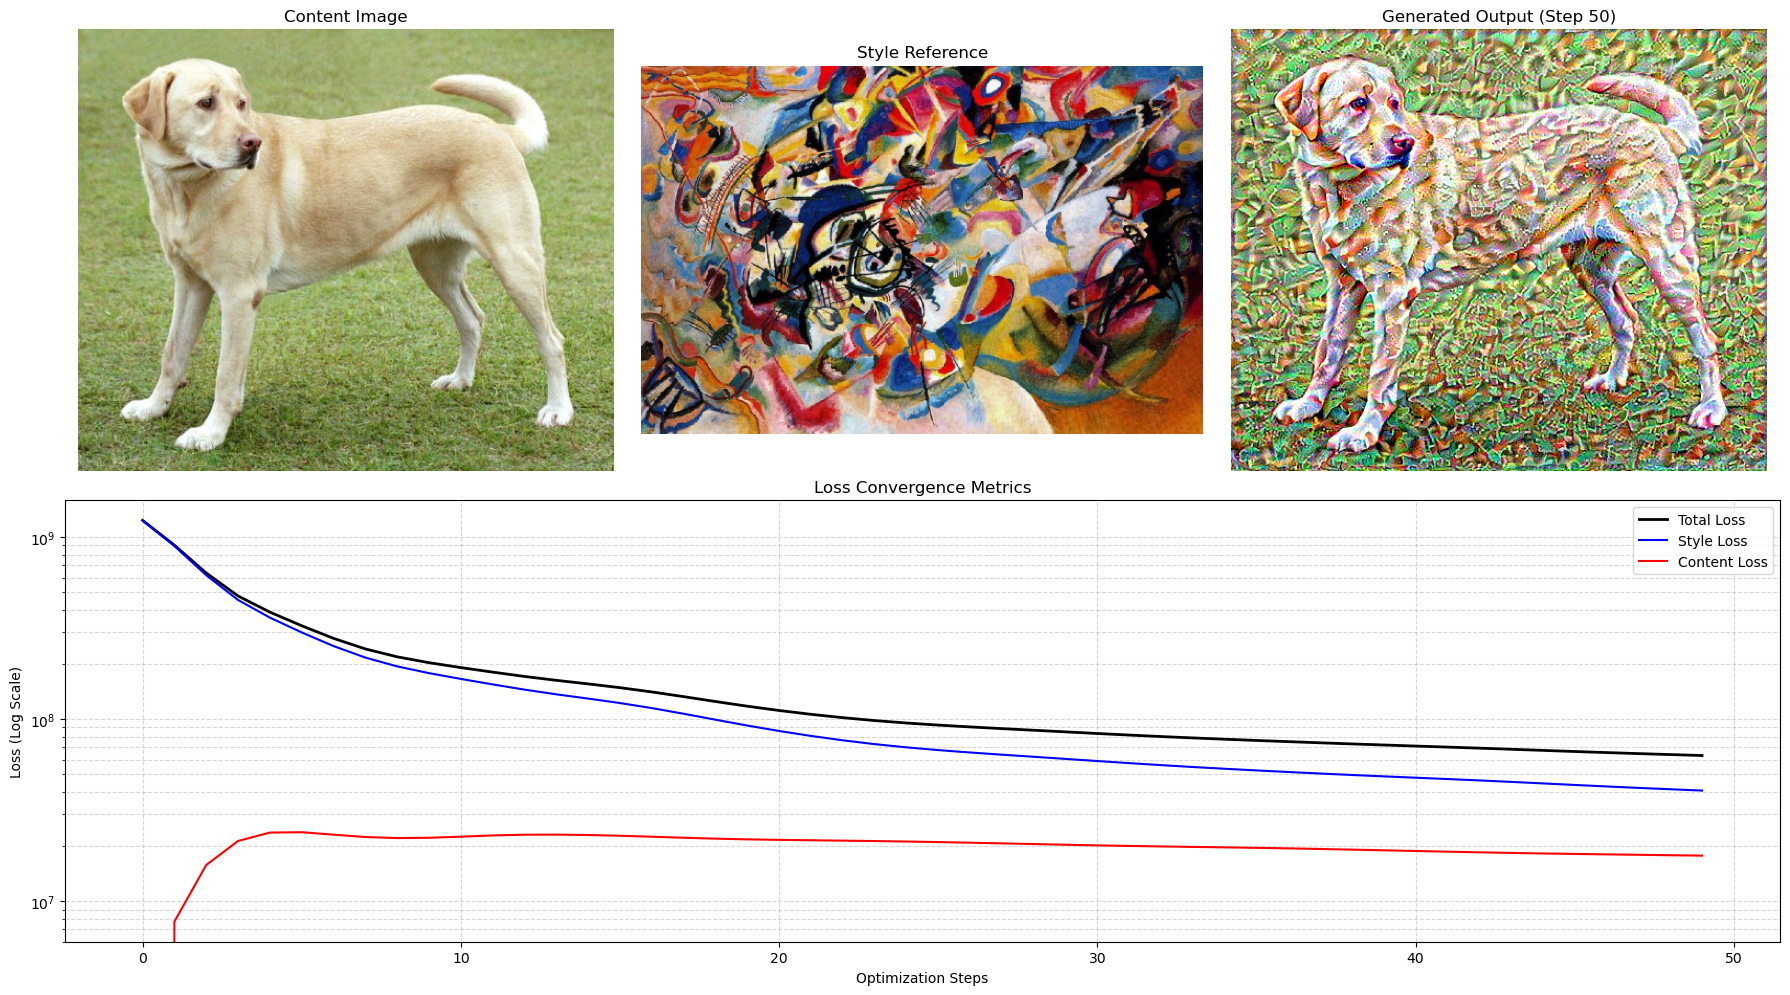

Current Progress: Finished Epoch 5/5

OPTIMIZATION FINISHED!
Total time taken: 2.00 minutes.


In [5]:
# 6. Main Execution Loop
import time
from IPython.display import clear_output

epochs = 5
steps_per_epoch = 10
step = 0
history = {'total': [], 'style': [], 'content': []}

print("=== STARTING NEURAL STYLE TRANSFER ===")
print("System is preparing to optimize the image pixels...")
print(f"Plan: Run {epochs} epochs, with {steps_per_epoch} optimization steps per epoch.")
print("======================================\n")

start_time = time.time()

for n in range(epochs):
    print(f"\n>>> INITIATING EPOCH {n+1} of {epochs} <<<")
    
    for m in range(steps_per_epoch):
        step += 1
        step_start = time.time()
        
        print(f"  [Step {step}] Forward pass through VGG-19 & calculating gradients...", end="", flush=True)
        
        total_loss, s_loss, c_loss = train_step(image)
        
        step_end = time.time()
        duration = step_end - step_start
        
        t_loss_val = total_loss.numpy()[0] if isinstance(total_loss.numpy(), np.ndarray) else total_loss.numpy()
        s_loss_val = s_loss.numpy()
        c_loss_val = c_loss.numpy()
        
        # Save for the chart
        history['total'].append(t_loss_val)
        history['style'].append(s_loss_val)
        history['content'].append(c_loss_val)
        
        # Finish the print line with the time it took and the metrics
        print(f" Done in {duration:.2f}s!")
        print(f"           Loss Breakdown -> Total: {t_loss_val:.2e} | Style: {s_loss_val:.2e} | Content: {c_loss_val:.2e}")
        
    print(f"\n>>> EPOCH {n+1} COMPLETE <<<")
    print("Updating the visual dashboard with the newest generated image...")
    
    # Wait 2 seconds so you can read the text before the screen clears for the images
    time.sleep(2) 
    
    # Call the visualization function from the previous code
    display_dashboard(content_image, style_image, image.read_value(), history, step)
    
    # Reprint the epoch header because the dashboard cleared the screen
    print(f"Current Progress: Finished Epoch {n+1}/{epochs}")

total_time = time.time() - start_time
print("\n======================================")
print(f"OPTIMIZATION FINISHED!")
print(f"Total time taken: {total_time/60:.2f} minutes.")